# TP4 — Analyse de ventes e-commerce avec Spark SQL
## Nettoyage, jointures, fenêtres et optimisation
**Anwar Ezzirani · G4 · 5IIR · Data Science & AI**  
Module : Écosystème Big Data · Compte rendu et notebook exécuté

Ce document traite les 29 questions des parties 1 à 9 et la génération de la partie 0.
Les commandes, résultats et captures proviennent d'une exécution réelle sous Spark 4.0.0
dans Docker. Le chiffre d'affaires (CA) correspond exclusivement aux commandes livrées.
Les prix et les montants utilisent des décimaux pour éviter les approximations binaires.
Le CSV final, le notebook exécuté et le PDF sont les livrables de cette analyse.

## Partie 0 — Génération reproductible
Le code suivant est extrait de l'énoncé Word, sans modifier la graine `42` ni les
données générées. Les chemins `data_tp2` et `out_tp2`, ainsi que le nom d'application
`TP2 - Ventes`, sont ceux de l'énoncé du TP4. Les fichiers sont recréés à chaque exécution.

In [1]:
import os, csv, json, random
from datetime import date, timedelta
 
random.seed(42)
os.makedirs("data_tp2", exist_ok=True)
 
# ---------- produits.csv ----------
catalogue = {
    "Informatique": ["Clavier", "Souris", "Ecran", "Casque", "Webcam"],
    "Maison":       ["Lampe", "Chaise", "Bureau", "Etagere"],
    "Sport":        ["Ballon", "Raquette", "Tapis de yoga", "Haltères"],
}
produits_l, pid = [], 1
for cat, noms in catalogue.items():
    for n in noms:
        produits_l.append([pid, n, cat, random.choice([49, 79, 99, 149, 249, 399, 599])])
        pid += 1
produits_l[3][3] = "N/A"          # prix invalide (produit 4)
with open("data_tp2/produits.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["id_produit", "nom", "categorie", "prix"])
    w.writerows(produits_l)
 
# ---------- clients.json (un objet JSON par ligne) ----------
villes = ["Casablanca", "Rabat", "Fès", "Marrakech", "Tanger", "Agadir"]
prenoms = ["Sara", "Youssef", "Imane", "Omar", "Salma",
           "Hamza", "Khadija", "Anas", "Meryem", "Ayoub"]
familles = ["Alaoui", "Benani", "Cherkaoui", "Darif", "El Idrissi", "Fassi", "Tazi"]
with open("data_tp2/clients.json", "w", encoding="utf-8") as f:
    for i in range(1, 61):
        ville = random.choice(villes)
        if i % 7 == 0:
            ville = " " + ville.upper() + " "     # ville mal saisie
        c = {"id_client": i,
             "nom": random.choice(prenoms) + " " + random.choice(familles),
             "ville": ville,
             "date_inscription": (date(2024, 1, 1)
                                  + timedelta(days=random.randint(0, 364))).isoformat()}
        f.write(json.dumps(c, ensure_ascii=False) + "\n")
 
# ---------- commandes.csv ----------
statuts = ["livree", "livree", "livree", "annulee", "en_cours", "Livree", "LIVREE "]
cmd = []
for i in range(1, 3001):
    d = date(2025, 1, 1) + timedelta(days=random.randint(0, 364))
    cmd.append([i, random.randint(1, 54), random.randint(1, 13),
                random.randint(1, 5), d.isoformat(), random.choice(statuts)])
for k in range(0, 3000, 150):  cmd[k][3] = "abc"    # quantité invalide
for k in range(5, 3000, 200):  cmd[k][3] = -2       # quantité négative
for k in range(10, 3000, 300): cmd[k][4] = ""       # date manquante
for k in range(20, 3000, 500): cmd[k][1] = ""       # client manquant
cmd += random.sample(cmd, 40)                       # doublons exacts
with open("data_tp2/commandes.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["id_commande", "id_client", "id_produit",
                "quantite", "date_commande", "statut"])
    w.writerows(cmd)
 
print(sorted(os.listdir("data_tp2")))

['clients.json', 'commandes.csv', 'produits.csv']


## Partie 1 — Chargement avec schéma explicite
### Q1.1 — SparkSession et outils
`local[*]` exploite les processeurs disponibles dans le conteneur, ici limité à quatre.
Le paramètre de shuffle SQL vaut 8 ; l'optimisation adaptative peut ensuite fusionner
des partitions. Les conversions tolérantes permettront d'auditer les données sous ANSI.

In [2]:
import sys, platform, time, logging, io, contextlib
from pathlib import Path
from decimal import Decimal
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
ART, CAP = ROOT / "artifacts", ROOT / "artifacts/captures"
for dossier in (ART, CAP):
    dossier.mkdir(parents=True, exist_ok=True)
RESULTATS = {}
spark_home = os.environ.get("SPARK_HOME")
if spark_home:
    spark_python = Path(spark_home) / "python"
    for chemin in [spark_python, *spark_python.glob("lib/py4j-*-src.zip")]:
        if str(chemin) not in sys.path:
            sys.path.insert(0, str(chemin))
    os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.window import Window

spark = (SparkSession.builder.appName("TP2 - Ventes").master("local[*]")
         .config("spark.sql.shuffle.partitions", "8").config("spark.ui.port", "4040")
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("OFF")
print("Spark :", spark.version, "| Python :", platform.python_version())
print("Java :", sc._jvm.java.lang.System.getProperty("java.version"))
print("Application :", sc.appName, "| Master :", sc.master)
print("Parallélisme :", sc.defaultParallelism, "| Partitions SQL :", spark.conf.get("spark.sql.shuffle.partitions"))
print("ANSI :", spark.conf.get("spark.sql.ansi.enabled"))
print("Exécution UTC :", spark.sql("SELECT current_timestamp()").first()[0])
assert spark.version == "4.0.0" and sc.master == "local[*]"

def plan_texte(df, nom, mode="simple"):
    tampon = io.StringIO()
    with contextlib.redirect_stdout(tampon):
        df.explain(mode)
    texte = tampon.getvalue()
    (ART / (nom + ".txt")).write_text(texte, encoding="utf-8")
    print(texte)
    return texte

def capture_attendre(nom):
    if os.environ.get("TP4_CAPTURE") == "1":
        (ART / (nom + "_request.json")).write_text(json.dumps({"application":sc.applicationId}), encoding="utf-8")
        limite = time.monotonic() + 120
        while not (ART / (nom + "_done.json")).exists():
            if time.monotonic() > limite:
                raise TimeoutError("Capture non reçue : " + nom)
            time.sleep(1)

Spark : 4.0.0 | Python : 3.13.5
Java : 17.0.16
Application : TP2 - Ventes | Master : local[*]


Parallélisme : 4 | Partitions SQL : 8
ANSI : true


Exécution UTC : 2026-11-16 10:47:40.986846


### Q1.2 — Trois sources brutes
Les CSV sont chargés avec toutes les colonnes en `string` et un en-tête, afin de
conserver les valeurs invalides pour l'audit. Le JSON dispose aussi d'un schéma explicite
en chaînes. Attendus : 13 produits, 60 clients et 3 040 lignes de commandes.

In [3]:
produits_raw = (spark.read.schema("id_produit STRING, nom STRING, categorie STRING, prix STRING")
                .option("header", True).csv("data_tp2/produits.csv"))
clients_raw = (spark.read.schema("id_client STRING, nom STRING, ville STRING, date_inscription STRING")
               .json("data_tp2/clients.json"))
commandes_raw = (spark.read.schema("id_commande STRING, id_client STRING, id_produit STRING, quantite STRING, date_commande STRING, statut STRING")
                 .option("header", True).csv("data_tp2/commandes.csv"))
for nom, df in [("produits_raw", produits_raw), ("clients_raw", clients_raw), ("commandes_raw", commandes_raw)]:
    print("\nSOURCE :", nom, "| Lignes :", df.count())
    df.printSchema()
    df.show(5, truncate=False)
assert [produits_raw.count(), clients_raw.count(), commandes_raw.count()] == [13, 60, 3040]


SOURCE : produits_raw | Lignes : 13
root
 |-- id_produit: string (nullable = true)
 |-- nom: string (nullable = true)
 |-- categorie: string (nullable = true)
 |-- prix: string (nullable = true)



+----------+-------+------------+----+
|id_produit|nom    |categorie   |prix|
+----------+-------+------------+----+
|1         |Clavier|Informatique|399 |
|2         |Souris |Informatique|49  |
|3         |Ecran  |Informatique|49  |
|4         |Casque |Informatique|N/A |
|5         |Webcam |Informatique|99  |
+----------+-------+------------+----+
only showing top 5 rows

SOURCE : clients_raw | Lignes : 60
root
 |-- id_client: string (nullable = true)
 |-- nom: string (nullable = true)
 |-- ville: string (nullable = true)
 |-- date_inscription: string (nullable = true)



+---------+---------------+----------+----------------+
|id_client|nom            |ville     |date_inscription|
+---------+---------------+----------+----------------+
|1        |Ayoub Darif    |Casablanca|2024-01-17      |
|2        |Youssef Benani |Casablanca|2024-04-29      |
|3        |Ayoub Alaoui   |Tanger    |2024-10-14      |
|4        |Meryem Darif   |Rabat     |2024-04-22      |
|5        |Ayoub Cherkaoui|Marrakech |2024-01-04      |
+---------+---------------+----------+----------------+
only showing top 5 rows

SOURCE : commandes_raw | Lignes : 3040
root
 |-- id_commande: string (nullable = true)
 |-- id_client: string (nullable = true)
 |-- id_produit: string (nullable = true)
 |-- quantite: string (nullable = true)
 |-- date_commande: string (nullable = true)
 |-- statut: string (nullable = true)



+-----------+---------+----------+--------+-------------+-------+
|id_commande|id_client|id_produit|quantite|date_commande|statut |
+-----------+---------+----------+--------+-------------+-------+
|1          |51       |8         |abc     |2025-05-05   |livree |
|2          |7        |11        |4       |2025-02-18   |livree |
|3          |27       |8         |1       |2025-08-05   |Livree |
|4          |42       |2         |1       |2025-12-01   |annulee|
|5          |52       |2         |2       |2025-06-23   |livree |
+-----------+---------+----------+--------+-------------+-------+
only showing top 5 rows


## Partie 2 — Audit de la qualité
### Q2.1 — Valeurs manquantes en une projection
Une valeur est manquante si elle est nulle ou vide après `trim`. Chaque expression
compte uniquement les lignes répondant à cette condition. Une seule requête `select`
calcule les six compteurs, avant toute suppression des doublons.

In [4]:
audit_manquants = commandes_raw.select(*[
    F.count(F.when(F.col(c).isNull() | (F.trim(F.col(c)) == ""), 1)).alias(c)
    for c in commandes_raw.columns])
audit_manquants.show()
RESULTATS["manquants_bruts"] = audit_manquants.first().asDict()
assert RESULTATS["manquants_bruts"] == {"id_commande":0,"id_client":7,"id_produit":0,
                                       "quantite":0,"date_commande":10,"statut":0}

+-----------+---------+----------+--------+-------------+------+
|id_commande|id_client|id_produit|quantite|date_commande|statut|
+-----------+---------+----------+--------+-------------+------+
|          0|        7|         0|       0|           10|     0|
+-----------+---------+----------+--------+-------------+------+



### Q2.2 — Doublons exacts et statuts bruts
Quarante lignes sont des copies exactes. Les variantes `livree`, `Livree` et `LIVREE `
décrivent le même statut métier : compter les chaînes brutes séparément sous-estimerait
le nombre de livraisons. On distingue trois statuts métier après normalisation.

In [5]:
nb_doublons = commandes_raw.count() - commandes_raw.dropDuplicates().count()
statuts_bruts = commandes_raw.groupBy("statut").count().orderBy(F.desc("count"), "statut")
print("Doublons exacts :", nb_doublons)
statuts_bruts.show(truncate=False)
print("Statuts distincts bruts :", statuts_bruts.count())
RESULTATS["doublons_exacts"] = nb_doublons
RESULTATS["statuts_bruts"] = [r.asDict() for r in statuts_bruts.collect()]
assert nb_doublons == 40 and statuts_bruts.count() == 5

Doublons exacts : 40


+--------+-----+
|statut  |count|
+--------+-----+
|livree  |1260 |
|annulee |476  |
|Livree  |465  |
|LIVREE  |426  |
|en_cours|413  |
+--------+-----+

Statuts distincts bruts : 5


### Q2.3 — Quantités invalides ou négatives
`try_cast("int")` retourne `NULL` pour `abc`, même en mode ANSI. On détecte les
conversions impossibles et les quantités négatives. Le nettoyage éliminera aussi zéro.
L'audit porte sur les lignes brutes, doublons compris : 35 lignes sont concernées ici.

In [6]:
qte_convertie = F.col("quantite").try_cast("int")
quantites_invalides = commandes_raw.filter(qte_convertie.isNull() | (qte_convertie < 0))
print("Quantités invalides ou négatives :", quantites_invalides.count())
quantites_invalides.orderBy(F.col("id_commande").try_cast("int")).show(5, truncate=False)
RESULTATS["quantites_invalides_brutes"] = quantites_invalides.count()
assert quantites_invalides.count() == 35

Quantités invalides ou négatives : 35
+-----------+---------+----------+--------+-------------+-------+
|id_commande|id_client|id_produit|quantite|date_commande|statut |
+-----------+---------+----------+--------+-------------+-------+
|1          |51       |8         |abc     |2025-05-05   |livree |
|6          |35       |8         |-2      |2025-04-08   |annulee|
|151        |25       |8         |abc     |2025-09-25   |livree |
|206        |44       |5         |-2      |2025-11-20   |Livree |
|301        |43       |5         |abc     |2025-09-27   |livree |
+-----------+---------+----------+--------+-------------+-------+
only showing top 5 rows


### Q2.4 — Prix invalide
Le produit 4, Casque, de catégorie Informatique, a le prix `N/A`. Il doit être
imputé avant les calculs de CA, plutôt que supprimé ou remplacé par zéro.

In [7]:
prix_invalides = produits_raw.filter(F.col("prix").try_cast("decimal(18,2)").isNull())
prix_invalides.show(truncate=False)
assert [r.id_produit for r in prix_invalides.collect()] == ["4"]

+----------+------+------------+----+
|id_produit|nom   |categorie   |prix|
+----------+------+------------+----+
|4         |Casque|Informatique|N/A |
+----------+------+------------+----+



## Partie 3 — Nettoyage et typage
### Q3.1 — Commandes, règles R1 à R4
L'ordre est respecté : dédoublonner les lignes exactes, convertir les types, normaliser
le statut puis filtrer. Les trois identifiants et la quantité deviennent des entiers,
la date devient un `date`, le statut est passé en minuscules sans espaces externes.
Sur les 3 000 lignes distinctes, 51 échouent aux critères de validité. Les compteurs
par motif peuvent se chevaucher sur d'autres jeux de données ; on filtre leur union.

In [8]:
cmd_uniques = commandes_raw.dropDuplicates()
cmd_types = cmd_uniques.select(
    *[F.col(c).try_cast("int").alias(c) for c in ["id_commande","id_client","id_produit","quantite"]],
    F.col("date_commande").try_cast("date").alias("date_commande"),
    F.lower(F.trim("statut")).alias("statut"))
valide = (F.col("quantite").isNotNull() & (F.col("quantite") > 0)
          & F.col("date_commande").isNotNull() & F.col("id_client").isNotNull())
commandes = cmd_types.filter(valide)
print("Avant :", commandes_raw.count(), "| Sans doublons :", cmd_uniques.count(), "| Après :", commandes.count())
print("Lignes distinctes rejetées :", cmd_types.count() - commandes.count())
commandes.printSchema()
commandes.groupBy("statut").count().orderBy("statut").show()
RESULTATS["nettoyage"] = {"brutes":3040,"distinctes":cmd_uniques.count(),"propres":commandes.count()}
assert commandes.count() == 2949
assert commandes.filter(F.col("statut") == "livree").count() == 2089

Avant : 3040 | Sans doublons : 3000 | Après : 2949


Lignes distinctes rejetées : 51
root
 |-- id_commande: integer (nullable = true)
 |-- id_client: integer (nullable = true)
 |-- id_produit: integer (nullable = true)
 |-- quantite: integer (nullable = true)
 |-- date_commande: date (nullable = true)
 |-- statut: string (nullable = true)



+--------+-----+
|  statut|count|
+--------+-----+
| annulee|  463|
|en_cours|  397|
|  livree| 2089|
+--------+-----+



### Q3.2 — Produits et imputation par catégorie
Après conversion, la fenêtre calcule la moyenne des prix valides de la catégorie.
Pour Casque : (399 + 49 + 49 + 99) / 4 = 149 MAD. `coalesce` conserve les prix
valides et ne remplace que les prix nuls. Le résultat est exprimé en `decimal(18,2)`.
Si une catégorie ne contenait aucun prix valide, sa moyenne resterait nulle ; ce cas
serait à traiter explicitement. L'assertion vérifie son absence dans ce jeu de données.

In [9]:
p_types = produits_raw.dropDuplicates().select(
    F.col("id_produit").try_cast("int").alias("id_produit"), "nom", "categorie",
    F.col("prix").try_cast("decimal(18,2)").alias("prix"))
w_categorie = Window.partitionBy("categorie")
produits = p_types.withColumn("prix", F.coalesce(F.col("prix"), F.avg("prix").over(w_categorie))
                               .cast("decimal(18,2)"))
produits.orderBy("id_produit").show(truncate=False)
produits.printSchema()
assert produits.filter(F.col("prix").isNull()).count() == 0
assert produits.filter(F.col("id_produit") == 4).first().prix == Decimal("149.00")

+----------+-------------+------------+------+
|id_produit|nom          |categorie   |prix  |
+----------+-------------+------------+------+
|1         |Clavier      |Informatique|399.00|
|2         |Souris       |Informatique|49.00 |
|3         |Ecran        |Informatique|49.00 |
|4         |Casque       |Informatique|149.00|
|5         |Webcam       |Informatique|99.00 |
|6         |Lampe        |Maison      |79.00 |
|7         |Chaise       |Maison      |79.00 |
|8         |Bureau       |Maison      |79.00 |
|9         |Etagere      |Maison      |399.00|
|10        |Ballon       |Sport       |49.00 |
|11        |Raquette     |Sport       |399.00|
|12        |Tapis de yoga|Sport       |399.00|
|13        |Haltères     |Sport       |249.00|
+----------+-------------+------------+------+

root
 |-- id_produit: integer (nullable = true)
 |-- nom: string (nullable = true)
 |-- categorie: string (nullable = true)
 |-- prix: decimal(18,2) (nullable = true)



### Q3.3 — Clients et villes
Les identifiants deviennent des entiers, les inscriptions des dates et les villes
sont normalisées avec `initcap(trim(...))`. `FÈS` devient `Fès`. On retrouve six villes,
sans créer artificiellement des villes supplémentaires à partir de la casse.

In [10]:
clients = clients_raw.dropDuplicates().select(
    F.col("id_client").try_cast("int").alias("id_client"), "nom",
    F.initcap(F.trim("ville")).alias("ville"),
    F.col("date_inscription").try_cast("date").alias("date_inscription"))
clients.printSchema()
villes = [r.ville for r in clients.select("ville").distinct().orderBy("ville").collect()]
print("Villes distinctes :", villes, "| Effectif :", len(villes))
assert set(villes) == {"Casablanca","Rabat","Fès","Marrakech","Tanger","Agadir"}
assert clients.count() == 60
RESULTATS["villes"] = villes

root
 |-- id_client: integer (nullable = true)
 |-- nom: string (nullable = true)
 |-- ville: string (nullable = true)
 |-- date_inscription: date (nullable = true)

Villes distinctes : ['Agadir', 'Casablanca', 'Fès', 'Marrakech', 'Rabat', 'Tanger'] | Effectif : 6


## Partie 4 — Analyses SQL sur vues temporaires
### Q4.1 — CA global des commandes livrées
Les vues rendent accessibles les trois DataFrames propres dans la session. La jointure
sur le produit fournit le prix imputé si nécessaire. Seul `statut = 'livree'` contribue
au CA. Le nombre de commandes correspond ici au nombre de lignes : chaque commande
possède un seul produit et les identifiants sont uniques après nettoyage.

In [11]:
for nom, df in [("produits",produits),("clients",clients),("commandes",commandes)]:
    df.createOrReplaceTempView(nom)
assert commandes.select("id_commande").distinct().count() == commandes.count()
assert produits.select("id_produit").distinct().count() == produits.count()
assert clients.select("id_client").distinct().count() == clients.count()
total_sql = spark.sql("""
    SELECT SUM(c.quantite * p.prix) AS ca_total, COUNT(*) AS nb_commandes
    FROM commandes c JOIN produits p ON c.id_produit = p.id_produit
    WHERE c.statut = 'livree'
""")
total_sql.show()
total = total_sql.first()
RESULTATS["total"] = total.asDict()
assert total.nb_commandes == 2089

+----------+------------+
|  ca_total|nb_commandes|
+----------+------------+
|1215123.00|        2089|
+----------+------------+



### Q4.2 — CA, nombre de commandes et panier moyen par catégorie
Le panier moyen est le CA divisé par le nombre de commandes livrées de la catégorie.
L'arrondi à deux décimales ne sert qu'à la présentation ; les calculs conservent leur
précision. Le tri est décroissant sur le CA, avec un second critère pour les égalités.

In [12]:
ca_categories = spark.sql("""
    SELECT p.categorie, SUM(c.quantite * p.prix) AS ca, COUNT(*) AS nb_commandes,
           SUM(c.quantite * p.prix) / COUNT(*) AS panier_moyen
    FROM commandes c JOIN produits p ON c.id_produit = p.id_produit
    WHERE c.statut = 'livree'
    GROUP BY p.categorie ORDER BY ca DESC, p.categorie
""")
ca_categories.withColumn("panier_moyen", F.round("panier_moyen",2)).show()
RESULTATS["ca_categories"] = [r.asDict() for r in ca_categories.collect()]

+------------+---------+------------+------------+
|   categorie|       ca|nb_commandes|panier_moyen|
+------------+---------+------------+------------+
|       Sport|574687.00|         685|      838.96|
|Informatique|354311.00|         800|      442.89|
|      Maison|286125.00|         604|      473.72|
+------------+---------+------------+------------+



### Q4.3 — CA mensuel et meilleur mois
`date_format` construit une clé `yyyy-MM`, dont le tri alphabétique respecte l'ordre
chronologique. Le classement du meilleur mois est calculé sur les valeurs, pas déduit
de l'ordre des lignes du tableau.

In [13]:
ca_mensuel = spark.sql("""
    SELECT date_format(c.date_commande, 'yyyy-MM') AS mois, SUM(c.quantite * p.prix) AS ca
    FROM commandes c JOIN produits p ON c.id_produit = p.id_produit
    WHERE c.statut = 'livree'
    GROUP BY date_format(c.date_commande, 'yyyy-MM') ORDER BY mois
""")
ca_mensuel.show(12)
meilleur_mois = ca_mensuel.orderBy(F.desc("ca"), "mois").first()
print("Meilleur mois :", meilleur_mois.mois, "| CA :", meilleur_mois.ca, "MAD")
RESULTATS["ca_mensuel"] = [r.asDict() for r in ca_mensuel.collect()]
RESULTATS["meilleur_mois"] = meilleur_mois.asDict()

+-------+---------+
|   mois|       ca|
+-------+---------+
|2025-01|118017.00|
|2025-02| 98790.00|
|2025-03|109451.00|
|2025-04| 81453.00|
|2025-05| 86787.00|
|2025-06|114252.00|
|2025-07|106081.00|
|2025-08|114002.00|
|2025-09| 92077.00|
|2025-10| 90417.00|
|2025-11| 99390.00|
|2025-12|104406.00|
+-------+---------+



Meilleur mois : 2025-01 | CA : 118017.00 MAD


### Q4.4 — Top cinq des produits par CA
On regroupe par identifiant, nom et catégorie pour éviter de fusionner d'éventuels
homonymes du catalogue. Les quantités concernent uniquement les commandes livrées.

In [14]:
top_produits = spark.sql("""
    SELECT p.id_produit, p.nom, p.categorie, SUM(c.quantite) AS quantite_totale,
           SUM(c.quantite * p.prix) AS ca
    FROM commandes c JOIN produits p ON c.id_produit = p.id_produit
    WHERE c.statut = 'livree'
    GROUP BY p.id_produit, p.nom, p.categorie
""")
top_produits.orderBy(F.desc("ca"), "id_produit").limit(5).show(truncate=False)
RESULTATS["top5_produits"] = [r.asDict() for r in top_produits.orderBy(F.desc("ca"),"id_produit").limit(5).collect()]

+----------+-------------+------------+---------------+---------+
|id_produit|nom          |categorie   |quantite_totale|ca       |
+----------+-------------+------------+---------------+---------+
|11        |Raquette     |Sport       |552            |220248.00|
|12        |Tapis de yoga|Sport       |517            |206283.00|
|1         |Clavier      |Informatique|491            |195909.00|
|9         |Etagere      |Maison      |451            |179949.00|
|13        |Haltères     |Sport       |485            |120765.00|
+----------+-------------+------------+---------------+---------+



## Partie 5 — Jointures en API DataFrame
### Q5.1 — Construction de `ventes`
On renomme les champs `nom` avant les jointures pour distinguer client et produit.
Le résultat respecte les neuf colonnes demandées, dont `nom` pour le produit.
Les vérifications des clés garantissent qu'aucune commande propre ne perd son client
ou son produit. Le rapprochement des trois sources conserve donc toutes les livraisons.

In [15]:
p_jointure = produits.withColumnRenamed("nom", "produit")
cl_jointure = clients.withColumnRenamed("nom", "nom_client")
ventes = (commandes.filter(F.col("statut") == "livree")
          .join(p_jointure, "id_produit", "inner")
          .join(cl_jointure, "id_client", "inner")
          .select("id_commande", "date_commande", "nom_client", "ville",
                  F.col("produit").alias("nom"), "categorie", "quantite", "prix",
                  (F.col("quantite") * F.col("prix")).alias("ca")))
ventes.orderBy("id_commande").show(5, truncate=False)
ventes.printSchema()
print("Ventes enrichies :", ventes.count())
assert ventes.count() == total.nb_commandes
assert commandes.join(produits, "id_produit", "left_anti").count() == 0
assert commandes.join(clients, "id_client", "left_anti").count() == 0

+-----------+-------------+---------------+---------+--------+------------+--------+------+-------+
|id_commande|date_commande|nom_client     |ville    |nom     |categorie   |quantite|prix  |ca     |
+-----------+-------------+---------------+---------+--------+------------+--------+------+-------+
|2          |2025-02-18   |Omar Tazi      |Rabat    |Raquette|Sport       |4       |399.00|1596.00|
|3          |2025-08-05   |Imane Cherkaoui|Marrakech|Bureau  |Maison      |1       |79.00 |79.00  |
|5          |2025-06-23   |Hamza Darif    |Marrakech|Souris  |Informatique|2       |49.00 |98.00  |
|7          |2025-04-04   |Salma Fassi    |Rabat    |Bureau  |Maison      |2       |79.00 |158.00 |
|8          |2025-02-08   |Ayoub Darif    |Agadir   |Haltères|Sport       |5       |249.00|1245.00|
+-----------+-------------+---------------+---------+--------+------------+--------+------+-------+
only showing top 5 rows
root
 |-- id_commande: integer (nullable = true)
 |-- date_commande: date (n

Ventes enrichies : 2089


### Q5.2 — CA par ville et réconciliation
La somme des CA des six villes doit retrouver exactement le CA global de Q4.1.
Les décimaux permettent une égalité exacte, sans tolérance sur un nombre flottant.

In [16]:
ca_villes = ventes.groupBy("ville").agg(F.sum("ca").alias("ca")).orderBy(F.desc("ca"), "ville")
ca_villes.show()
somme_villes = ca_villes.agg(F.sum("ca")).first()[0]
print("Somme des villes :", somme_villes, "| Total SQL :", total.ca_total)
assert somme_villes == total.ca_total
RESULTATS["ca_villes"] = [r.asDict() for r in ca_villes.collect()]

+----------+---------+
|     ville|       ca|
+----------+---------+
|     Rabat|253369.00|
|    Tanger|220226.00|
|       Fès|209395.00|
| Marrakech|208387.00|
|    Agadir|170305.00|
|Casablanca|153441.00|
+----------+---------+



Somme des villes : 1215123.00 | Total SQL : 1215123.00


### Q5.3 — Clients sans commande propre
La jointure `left_anti` conserve les clients n'ayant aucune correspondance dans
`commandes`, quel que soit le statut de la commande. Ce n'est donc pas seulement
la recherche des clients sans livraison. Les identifiants 55 à 60 sont attendus.

In [17]:
sans_commandes = clients.join(commandes, "id_client", "left_anti").orderBy("id_client")
sans_commandes.show(truncate=False)
print("Clients sans commande propre :", sans_commandes.count())
assert [r.id_client for r in sans_commandes.collect()] == list(range(55,61))
RESULTATS["clients_sans_commande"] = [r.asDict() for r in sans_commandes.collect()]

+---------+------------------+----------+----------------+
|id_client|nom               |ville     |date_inscription|
+---------+------------------+----------+----------------+
|55       |Omar El Idrissi   |Tanger    |2024-04-22      |
|56       |Youssef Fassi     |Casablanca|2024-11-19      |
|57       |Omar Alaoui       |Casablanca|2024-01-17      |
|58       |Youssef El Idrissi|Fès       |2024-05-01      |
|59       |Anas Benani       |Fès       |2024-10-03      |
|60       |Ayoub El Idrissi  |Rabat     |2024-08-30      |
+---------+------------------+----------+----------------+



Clients sans commande propre : 6


### Q5.4 — Choix de jointure
| Type | Lignes retournées |
|---|---|
| `inner` | Les combinaisons dont la clé existe dans les deux tables. |
| `left` | Toutes les lignes de gauche ; valeurs de droite à `NULL` sans correspondance. |
| `left_semi` | Seulement les colonnes et lignes de gauche ayant au moins une correspondance. |
| `left_anti` | Seulement les colonnes et lignes de gauche sans correspondance. |

À la Q5.1, un `left` différerait d'un `inner` si une commande référençait un produit
ou un client absent du référentiel. Elle serait conservée, avec les attributs manquants
à `NULL`. Ici les vérifications de clés montrent qu'il n'y a aucun cas de ce type.
Une jointure peut multiplier les lignes si le référentiel contient plusieurs occurrences
d'une même clé ; l'unicité a également été vérifiée avant les analyses.

## Partie 6 — Fonctions de fenêtre
### Q6.1 — Deux meilleurs rangs par catégorie
On calcule d'abord le CA par produit, puis `dense_rank` au sein de chaque catégorie.
Le rang ne laisse pas de trou en cas d'égalité. Garder `rang <= 2` peut donc retenir
plus de deux produits si des CA sont égaux : le classement demandé respecte les ex æquo.

In [18]:
w_classement = Window.partitionBy("categorie").orderBy(F.desc("ca"))
top2_categories = (top_produits.withColumn("rang", F.dense_rank().over(w_classement))
                   .filter(F.col("rang") <= 2).orderBy("categorie", "rang", "id_produit"))
top2_categories.show(truncate=False)
RESULTATS["top2_categories"] = [r.asDict() for r in top2_categories.collect()]

+----------+-------------+------------+---------------+---------+----+
|id_produit|nom          |categorie   |quantite_totale|ca       |rang|
+----------+-------------+------------+---------------+---------+----+
|1         |Clavier      |Informatique|491            |195909.00|1   |
|4         |Casque       |Informatique|409            |60941.00 |2   |
|9         |Etagere      |Maison      |451            |179949.00|1   |
|8         |Bureau       |Maison      |496            |39184.00 |2   |
|11        |Raquette     |Sport       |552            |220248.00|1   |
|12        |Tapis de yoga|Sport       |517            |206283.00|2   |
+----------+-------------+------------+---------------+---------+----+



### Q6.2 — CA cumulé et variation mensuelle
Le cumul utilise toutes les lignes du début à la ligne courante. `lag` récupère
le CA du mois précédent et la variation vaut 100 × (CA courant − CA précédent) / CA précédent.
Le premier mois n'a pas de référence : sa variation reste `NULL`. On protège aussi la
division contre zéro. Les douze mois sont présents ; sinon, il faudrait compléter
un calendrier avant d'interpréter `lag` comme le mois civil précédent.

In [19]:
w_mois = Window.orderBy("mois")
evolution = (ca_mensuel.withColumn("ca_cumule", F.sum("ca").over(
                w_mois.rowsBetween(Window.unboundedPreceding, Window.currentRow)))
             .withColumn("ca_precedent", F.lag("ca").over(w_mois))
             .withColumn("variation_pct", F.when(F.col("ca_precedent").isNotNull() & (F.col("ca_precedent") != 0),
                 F.round((F.col("ca") - F.col("ca_precedent")) / F.col("ca_precedent") * 100, 2))))
evolution.show(12)
assert ca_mensuel.count() == 12
assert evolution.orderBy("mois").first().variation_pct is None
assert evolution.orderBy(F.desc("mois")).first().ca_cumule == total.ca_total
RESULTATS["evolution_mensuelle"] = [r.asDict() for r in evolution.orderBy("mois").collect()]

+-------+---------+----------+------------+-------------+
|   mois|       ca| ca_cumule|ca_precedent|variation_pct|
+-------+---------+----------+------------+-------------+
|2025-01|118017.00| 118017.00|        NULL|         NULL|
|2025-02| 98790.00| 216807.00|   118017.00|       -16.29|
|2025-03|109451.00| 326258.00|    98790.00|        10.79|
|2025-04| 81453.00| 407711.00|   109451.00|       -25.58|
|2025-05| 86787.00| 494498.00|    81453.00|         6.55|
|2025-06|114252.00| 608750.00|    86787.00|        31.65|
|2025-07|106081.00| 714831.00|   114252.00|        -7.15|
|2025-08|114002.00| 828833.00|   106081.00|         7.47|
|2025-09| 92077.00| 920910.00|   114002.00|       -19.23|
|2025-10| 90417.00|1011327.00|    92077.00|        -1.80|
|2025-11| 99390.00|1110717.00|    90417.00|         9.92|
|2025-12|104406.00|1215123.00|    99390.00|         5.05|
+-------+---------+----------+------------+-------------+



## Partie 7 — Segmentation des clients
### Q7.1 — Segmentation en API DataFrame
On rattache `id_client` aux ventes via l'identifiant unique de commande, car les neuf
colonnes demandées en Q5.1 ne contiennent pas cet identifiant. Il faut regrouper par
identifiant, et non par nom : des clients peuvent être homonymes. Les seuils sont inclusifs.
La segmentation porte ici sur les clients ayant au moins une vente livrée. Les six
clients sans commande ne sont pas implicitement ajoutés au segment Bronze.

In [20]:
ventes_clients = ventes.join(commandes.select("id_commande", "id_client"), "id_commande", "inner")
ca_clients = ventes_clients.groupBy("id_client").agg(F.sum("ca").alias("ca_client"))
segments = ca_clients.withColumn("segment", F.when(F.col("ca_client") >= 25000, "Gold")
                                .when(F.col("ca_client") >= 20000, "Silver").otherwise("Bronze"))
effectifs_segments = segments.groupBy("segment").count().orderBy("segment")
effectifs_segments.show()
print("Clients segmentés :", segments.count())
assert segments.count() == 54
RESULTATS["segments"] = [r.asDict() for r in effectifs_segments.collect()]

+-------+-----+
|segment|count|
+-------+-----+
| Bronze|   22|
|   Gold|   16|
| Silver|   16|
+-------+-----+



Clients segmentés : 54


### Q7.2 — Même segmentation en SQL pur et top cinq
La sous-requête agrège les commandes propres livrées jointes aux prix. `CASE WHEN`
reprend les mêmes seuils. On joint ensuite le référentiel pour afficher le nom et la ville.
La comparaison des résultats dans les deux sens vérifie l'équivalence avec l'API DataFrame.

In [21]:
segments_sql = spark.sql("""
    WITH ca_par_client AS (
        SELECT c.id_client, SUM(c.quantite * p.prix) AS ca_client
        FROM commandes c JOIN produits p ON c.id_produit = p.id_produit
        WHERE c.statut = 'livree' GROUP BY c.id_client
    )
    SELECT id_client, ca_client,
           CASE WHEN ca_client >= 25000 THEN 'Gold'
                WHEN ca_client >= 20000 THEN 'Silver' ELSE 'Bronze' END AS segment
    FROM ca_par_client
""")
segments_sql.createOrReplaceTempView("segments_clients")
top_clients = spark.sql("""
    SELECT s.id_client, cl.nom, cl.ville, s.ca_client, s.segment
    FROM segments_clients s JOIN clients cl ON s.id_client = cl.id_client
    ORDER BY s.ca_client DESC, s.id_client LIMIT 5
""")
top_clients.show(truncate=False)
assert segments.exceptAll(segments_sql).count() == 0
assert segments_sql.exceptAll(segments).count() == 0
RESULTATS["top5_clients"] = [r.asDict() for r in top_clients.collect()]

+---------+-----------------+------+---------+-------+
|id_client|nom              |ville |ca_client|segment|
+---------+-----------------+------+---------+-------+
|37       |Hamza Alaoui     |Fès   |41736.00 |Gold   |
|41       |Meryem El Idrissi|Fès   |38512.00 |Gold   |
|6        |Khadija Cherkaoui|Rabat |35376.00 |Gold   |
|43       |Meryem Alaoui    |Tanger|32523.00 |Gold   |
|39       |Salma El Idrissi |Agadir|31485.00 |Gold   |
+---------+-----------------+------+---------+-------+



## Partie 8 — Optimisation et plans d'exécution
### Q8.1 — Descente du filtre de catégorie
Le filtre est écrit après la jointure. Le plan optimisé le descend dans la branche
des produits, avant la jointure, car la catégorie provient exclusivement de cette table.
C'est la descente des prédicats (*predicate pushdown*) : on réduit les lignes à joindre.
Il faut distinguer cette réorganisation logique des filtres réellement délégués au
lecteur de fichiers, observés plus loin avec `PushedFilters`.

In [22]:
requete_sport = commandes.join(produits, "id_produit").filter(F.col("categorie") == "Sport")
plan_sport = plan_texte(requete_sport, "q8_1_sport", "formatted")
optimise = requete_sport._jdf.queryExecution().optimizedPlan().toString()
(ART / "q8_1_plan_logique_optimise.txt").write_text(optimise, encoding="utf-8")
print("EXTRAIT DU PLAN LOGIQUE OPTIMISÉ :")
for ligne in optimise.splitlines():
    if "Join Inner" in ligne or "Filter" in ligne:
        print(ligne)
assert "Sport" in optimise and "Filter" in optimise

== Physical Plan ==
AdaptiveSparkPlan (19)
+- Project (18)
   +- BroadcastHashJoin Inner BuildRight (17)
      :- HashAggregate (5)
      :  +- Exchange (4)
      :     +- HashAggregate (3)
      :        +- Filter (2)
      :           +- Scan csv  (1)
      +- BroadcastExchange (16)
         +- Project (15)
            +- Filter (14)
               +- Window (13)
                  +- Sort (12)
                     +- Exchange (11)
                        +- HashAggregate (10)
                           +- Exchange (9)
                              +- HashAggregate (8)
                                 +- Filter (7)
                                    +- Scan csv  (6)


(1) Scan csv 
Output [6]: [id_commande#9, id_client#10, id_produit#11, quantite#12, date_commande#13, statut#14]
Batched: false
Location: InMemoryFileIndex [file:/home/jovyan/work/data_tp2/commandes.csv]
PushedFilters: [IsNotNull(quantite), IsNotNull(date_commande), IsNotNull(id_client)]
ReadSchema: struct<id_commande:s

### Q8.2 — Stratégie automatique, sans diffusion et diffusion forcée
On matérialise chaque requête pour observer la stratégie réellement exécutée, y compris
les décisions adaptatives. Les seuils de diffusion statique et adaptative sont désactivés
ensemble, puis rétablis dans un `finally`. Le hint `broadcast` force la diffusion des
13 produits (filtrés ici sur Sport). Cette petite table tient en mémoire ; l'envoyer
aux exécutants évite de redistribuer la grande table pour cette jointure. Cela ne
supprime pas les autres shuffles nécessaires au nettoyage ou à l'imputation par fenêtre.

In [23]:
cles_broadcast = ["spark.sql.autoBroadcastJoinThreshold", "spark.sql.adaptive.autoBroadcastJoinThreshold"]
config_origine = {cle: spark.conf.get(cle, None) for cle in cles_broadcast}
def experience_jointure(diffuser=False):
    droite = F.broadcast(produits) if diffuser else produits
    return commandes.join(droite, "id_produit").filter(F.col("categorie") == "Sport")

auto = experience_jointure()
nb_auto = len(auto.collect())
print("AUTOMATIQUE :")
plan_auto = plan_texte(auto, "q8_2_automatique")
try:
    for cle in cles_broadcast:
        spark.conf.set(cle, "-1")
    sans_broadcast = experience_jointure()
    nb_sans = len(sans_broadcast.collect())
    print("SANS DIFFUSION AUTOMATIQUE :")
    plan_sans = plan_texte(sans_broadcast, "q8_2_sans_broadcast")
    force = experience_jointure(diffuser=True)
    nb_force = len(force.collect())
    print("BROADCAST EXPLICITE :")
    plan_force = plan_texte(force, "q8_2_broadcast_force")
    assert "BroadcastHashJoin" not in plan_sans
    assert "BroadcastHashJoin" in plan_force
    assert nb_auto == nb_sans == nb_force
finally:
    for cle, valeur in config_origine.items():
        if valeur is None:
            spark.conf.unset(cle)
        else:
            spark.conf.set(cle, valeur)
print("Configurations restaurées :", {c:spark.conf.get(c,None) for c in cles_broadcast})
RESULTATS["jointures_optimisation"] = {"automatique_broadcast":"BroadcastHashJoin" in plan_auto,
    "sans_broadcast_sort_merge":"SortMergeJoin" in plan_sans,
    "force_broadcast":"BroadcastHashJoin" in plan_force, "lignes_sport":nb_auto}
print("Stratégies constatées :", RESULTATS["jointures_optimisation"])

AUTOMATIQUE :
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=true
+- == Final Plan ==
   ResultQueryStage 4
   +- *(6) Project [id_produit#348, id_commande#346, id_client#347, quantite#349, date_commande#350, statut#351, nom#2, categorie#3, prix#515]
      +- *(6) BroadcastHashJoin [id_produit#348], [id_produit#513], Inner, BuildRight, false
         :- *(6) HashAggregate(keys=[id_produit#11, date_commande#13, id_commande#9, quantite#12, id_client#10, statut#14], functions=[])
         :  +- AQEShuffleRead coalesced
         :     +- ShuffleQueryStage 0
         :        +- Exchange hashpartitioning(id_produit#11, date_commande#13, id_commande#9, quantite#12, id_client#10, statut#14, 8), ENSURE_REQUIREMENTS, [plan_id=26268]
         :           +- *(1) HashAggregate(keys=[id_produit#11, date_commande#13, id_commande#9, quantite#12, id_client#10, statut#14], functions=[])
         :              +- *(1) Filter (((((((isnotnull(quantite#12) AND isnotnull(date_commande#13)) AND isnotnu

SANS DIFFUSION AUTOMATIQUE :
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=true
+- == Final Plan ==
   ResultQueryStage 5
   +- *(9) Project [id_produit#348, id_commande#346, id_client#347, quantite#349, date_commande#350, statut#351, nom#2, categorie#3, prix#515]
      +- *(9) SortMergeJoin [id_produit#348], [id_produit#513], Inner
         :- *(7) Sort [id_produit#348 ASC NULLS FIRST], false, 0
         :  +- AQEShuffleRead coalesced
         :     +- ShuffleQueryStage 3
         :        +- Exchange hashpartitioning(id_produit#348, 8), ENSURE_REQUIREMENTS, [plan_id=26755]
         :           +- *(4) HashAggregate(keys=[id_produit#11, date_commande#13, id_commande#9, quantite#12, id_client#10, statut#14], functions=[])
         :              +- AQEShuffleRead coalesced
         :                 +- ShuffleQueryStage 0
         :                    +- Exchange hashpartitioning(id_produit#11, date_commande#13, id_commande#9, quantite#12, id_client#10, statut#14, 8), ENSURE_REQUIR

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=true
+- == Final Plan ==
   ResultQueryStage 4
   +- *(6) Project [id_produit#348, id_commande#346, id_client#347, quantite#349, date_commande#350, statut#351, nom#2, categorie#3, prix#515]
      +- *(6) BroadcastHashJoin [id_produit#348], [id_produit#513], Inner, BuildRight, false
         :- *(6) HashAggregate(keys=[id_produit#11, date_commande#13, id_commande#9, quantite#12, id_client#10, statut#14], functions=[])
         :  +- AQEShuffleRead coalesced
         :     +- ShuffleQueryStage 0
         :        +- Exchange hashpartitioning(id_produit#11, date_commande#13, id_commande#9, quantite#12, id_client#10, statut#14, 8), ENSURE_REQUIREMENTS, [plan_id=26970]
         :           +- *(1) HashAggregate(keys=[id_produit#11, date_commande#13, id_commande#9, quantite#12, id_client#10, statut#14], functions=[])
         :              +- *(1) Filter (((((((isnotnull(quantite#12) AND isnotnull(date_commande#13)) AND isnotnull(id_client#1

### Q8.3 — Mesure du cache, trois essais de chaque côté
La même agrégation est exécutée trois fois avant le cache, puis trois fois après
matérialisation de `ventes.cache()`. Le remplissage du cache est chronométré séparément.
Les mesures sont celles de cette exécution ; les effets de préchauffage, de la JVM,
du système de fichiers et de la charge rendent cette expérience trop petite pour
constituer un benchmark général. On capture Storage pendant que le cache est actif,
puis on libère les données avec `unpersist()`.

In [24]:
from statistics import median
def mesurer_ville():
    debut = time.perf_counter()
    resultat = ventes.groupBy("ville").agg(F.sum("ca").alias("ca")).collect()
    return time.perf_counter() - debut, {r.ville:r.ca for r in resultat}

ventes.unpersist(blocking=True)
sans_cache = [mesurer_ville() for _ in range(3)]
ventes.cache()
debut = time.perf_counter()
assert ventes.count() == 2089
temps_remplissage = time.perf_counter() - debut
try:
    avec_cache = [mesurer_ville() for _ in range(3)]
    assert all(r == sans_cache[0][1] for _,r in sans_cache + avec_cache)
    print("Sans cache (s) :", [round(t,4) for t,_ in sans_cache])
    print("Avec cache (s) :", [round(t,4) for t,_ in avec_cache])
    print("Remplissage séparé (s) :", round(temps_remplissage,4))
    print("Stockage :", ventes.storageLevel)
    capture_attendre("storage")
finally:
    ventes.unpersist(blocking=True)
print("Cache libéré :", not ventes.is_cached)
RESULTATS["cache"] = {"sans_cache_s":[t for t,_ in sans_cache],"avec_cache_s":[t for t,_ in avec_cache],
    "remplissage_s":temps_remplissage,"mediane_sans_s":median(t for t,_ in sans_cache),
    "mediane_avec_s":median(t for t,_ in avec_cache)}

Sans cache (s) : [0.2553, 0.1875, 0.1997]
Avec cache (s) : [0.117, 0.0837, 0.0739]
Remplissage séparé (s) : 0.4499
Stockage : Disk Memory Deserialized 1x Replicated


Cache libéré : True


### Q8.4 — Plans DataFrame et SQL équivalents
Les deux versions calculent le CA par ville sur la même vue. Elles passent par
Catalyst et produisent les mêmes opérations essentielles (agrégations partielles,
échange, agrégation finale). Les identifiants de plan et les étapes adaptatives peuvent
différer. Le choix de l'API dépend donc surtout de la lisibilité et du contexte ;
SQL ne fournit pas automatiquement un moteur plus rapide que l'API DataFrame équivalente.

In [25]:
ventes.createOrReplaceTempView("ventes")
agg_ville_df = ventes.groupBy("ville").agg(F.sum("ca").alias("ca"))
agg_ville_sql = spark.sql("SELECT ville, SUM(ca) AS ca FROM ventes GROUP BY ville")
print("PLAN DATAFRAME :")
plan_texte(agg_ville_df, "q8_4_dataframe")
print("PLAN SQL :")
plan_texte(agg_ville_sql, "q8_4_sql")
assert agg_ville_df.exceptAll(agg_ville_sql).count() == 0
assert agg_ville_sql.exceptAll(agg_ville_df).count() == 0
print("Résultats identiques dans les deux sens.")

PLAN DATAFRAME :
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[ville#558], functions=[sum(ca#940)])
   +- Exchange hashpartitioning(ville#558, 8), ENSURE_REQUIREMENTS, [plan_id=29935]
      +- HashAggregate(keys=[ville#558], functions=[partial_sum(ca#940)])
         +- Project [ville#558, (cast(quantite#349 as decimal(10,0)) * prix#515) AS ca#940]
            +- BroadcastHashJoin [id_client#347], [id_client#557], Inner, BuildRight, false
               :- Project [id_client#347, quantite#349, prix#515]
               :  +- BroadcastHashJoin [id_produit#348], [id_produit#513], Inner, BuildRight, false
               :     :- HashAggregate(keys=[id_produit#11, date_commande#13, id_commande#9, quantite#12, id_client#10, statut#14], functions=[])
               :     :  +- Exchange hashpartitioning(id_produit#11, date_commande#13, id_commande#9, quantite#12, id_client#10, statut#14, 8), ENSURE_REQUIREMENTS, [plan_id=29913]
               :     :     +- Hash

Résultats identiques dans les deux sens.


## Partie 9 — Persistance et partitionnement
### Q9.1 — Parquet partitionné par mois
On ajoute `annee` et `mois` comme entiers. L'écriture `overwrite` remplace la sortie
du TP. Chaque dossier `mois=N` contient les lignes du mois correspondant ; les colonnes
de partition sont reconstruites à la lecture depuis le chemin. L'année est conservée
dans les données ; toutes les ventes de ce jeu sont de 2025.

In [26]:
ventes_dates = ventes.withColumn("annee", F.year("date_commande")).withColumn("mois", F.month("date_commande"))
sortie_parquet = ROOT / "out_tp2/ventes"
ventes_dates.write.mode("overwrite").partitionBy("mois").parquet(str(sortie_parquet))
print("ARBORESCENCE out_tp2/ventes :")
for fichier in sorted(sortie_parquet.rglob("*")):
    if not fichier.name.startswith("."):
        relatif = fichier.relative_to(sortie_parquet)
        print("  " * (len(relatif.parts)-1) + str(relatif) + ("/" if fichier.is_dir() else ""))
relecture = spark.read.parquet(str(sortie_parquet))
assert relecture.count() == ventes.count()
assert relecture.agg(F.sum("ca")).first()[0] == total.ca_total
assert len(list(sortie_parquet.glob("mois=*"))) == 12

ARBORESCENCE out_tp2/ventes :
_SUCCESS
mois=1/
  mois=1/part-00000-9e980153-78d6-46a1-9880-60d565961118.c000.snappy.parquet
mois=10/
  mois=10/part-00000-9e980153-78d6-46a1-9880-60d565961118.c000.snappy.parquet
mois=11/
  mois=11/part-00000-9e980153-78d6-46a1-9880-60d565961118.c000.snappy.parquet
mois=12/
  mois=12/part-00000-9e980153-78d6-46a1-9880-60d565961118.c000.snappy.parquet
mois=2/
  mois=2/part-00000-9e980153-78d6-46a1-9880-60d565961118.c000.snappy.parquet
mois=3/
  mois=3/part-00000-9e980153-78d6-46a1-9880-60d565961118.c000.snappy.parquet
mois=4/
  mois=4/part-00000-9e980153-78d6-46a1-9880-60d565961118.c000.snappy.parquet
mois=5/
  mois=5/part-00000-9e980153-78d6-46a1-9880-60d565961118.c000.snappy.parquet
mois=6/
  mois=6/part-00000-9e980153-78d6-46a1-9880-60d565961118.c000.snappy.parquet
mois=7/
  mois=7/part-00000-9e980153-78d6-46a1-9880-60d565961118.c000.snappy.parquet
mois=8/
  mois=8/part-00000-9e980153-78d6-46a1-9880-60d565961118.c000.snappy.parquet
mois=9/
  mois=9/par

### Q9.2 — Partition pruning et filtres Parquet
Le filtre `mois = 3` apparaît dans `PartitionFilters` : Spark écarte les autres
dossiers avant de lire leurs fichiers. La ville n'est pas une colonne de partition :
son filtre apparaît dans `DataFilters` et `PushedFilters`, pas dans `PartitionFilters`.
Parquet peut alors éviter des groupes de lignes selon leurs statistiques, sans garantir
l'élimination de fichiers entiers comme pour les partitions de mois.

In [27]:
mars = relecture.filter(F.col("mois") == 3)
ville_parquet = relecture.filter(F.col("ville") == "Casablanca")
print("FILTRE SUR LA PARTITION MOIS :")
plan_mars = plan_texte(mars, "q9_2_partition_mars", "formatted")
print("FILTRE SUR LA COLONNE VILLE :")
plan_ville = plan_texte(ville_parquet, "q9_2_ville", "formatted")
print("Lignes de mars :", mars.count(), "| Lignes de Casablanca :", ville_parquet.count())
assert "PartitionFilters" in plan_mars and "mois" in plan_mars
assert "PushedFilters" in plan_ville and "EqualTo(ville,Casablanca)" in plan_ville
RESULTATS["parquet"] = {"lignes":relecture.count(),"partitions_mois":12,"lignes_mars":mars.count()}

FILTRE SUR LA PARTITION MOIS :
== Physical Plan ==
* ColumnarToRow (2)
+- Scan parquet  (1)


(1) Scan parquet 
Output [11]: [id_commande#3650, date_commande#3651, nom_client#3652, ville#3653, nom#3654, categorie#3655, quantite#3656, prix#3657, ca#3658, annee#3659, mois#3660]
Batched: true
Location: InMemoryFileIndex [file:/home/jovyan/work/out_tp2/ventes]
PartitionFilters: [isnotnull(mois#3660), (mois#3660 = 3)]
ReadSchema: struct<id_commande:int,date_commande:date,nom_client:string,ville:string,nom:string,categorie:string,quantite:int,prix:decimal(18,2),ca:decimal(29,2),annee:int>

(2) ColumnarToRow [codegen id : 1]
Input [11]: [id_commande#3650, date_commande#3651, nom_client#3652, ville#3653, nom#3654, categorie#3655, quantite#3656, prix#3657, ca#3658, annee#3659, mois#3660]



FILTRE SUR LA COLONNE VILLE :
== Physical Plan ==
* Filter (3)
+- * ColumnarToRow (2)
   +- Scan parquet  (1)


(1) Scan parquet 
Output [11]: [id_commande#3650, date_commande#3651, nom_client#3652, ville#36

Lignes de mars : 189 | Lignes de Casablanca : 291


### Q9.3 — Rapport CSV unique, catégorie et mois
L'agrégation produit 36 lignes : trois catégories × douze mois. Spark écrit un dossier
contenant un unique `part-*.csv` et un marqueur `_SUCCESS`. On affiche tout le contenu
avec Python, puis copie ce même fichier sous un nom stable pour la livraison GitHub.

In [28]:
rapport = (ventes.withColumn("mois", F.date_format("date_commande", "yyyy-MM"))
           .groupBy("categorie", "mois").agg(F.sum("ca").alias("ca"))
           .orderBy("categorie", "mois"))
sortie_csv = ROOT / "out_tp2/rapport_ca"
rapport.coalesce(1).write.mode("overwrite").option("header", True).csv(str(sortie_csv))
fichiers_csv = list(sortie_csv.glob("part-*.csv"))
assert len(fichiers_csv) == 1 and rapport.count() == 36
contenu_csv = fichiers_csv[0].read_text(encoding="utf-8")
print(contenu_csv)
livrable_csv = ROOT / "Rapport_CA_TP4_Anwar_Ezzirani_G4.csv"
livrable_csv.write_bytes(fichiers_csv[0].read_bytes())
assert rapport.agg(F.sum("ca")).first()[0] == total.ca_total
print("CSV unique livré :", livrable_csv.name)

categorie,mois,ca
Informatique,2025-01,35488.00
Informatique,2025-02,26147.00
Informatique,2025-03,29241.00
Informatique,2025-04,27263.00
Informatique,2025-05,30193.00
Informatique,2025-06,24902.00
Informatique,2025-07,31906.00
Informatique,2025-08,42962.00
Informatique,2025-09,25664.00
Informatique,2025-10,30399.00
Informatique,2025-11,25374.00
Informatique,2025-12,24772.00
Maison,2025-01,26724.00
Maison,2025-02,24820.00
Maison,2025-03,25377.00
Maison,2025-04,17389.00
Maison,2025-05,21075.00
Maison,2025-06,26957.00
Maison,2025-07,27648.00
Maison,2025-08,18989.00
Maison,2025-09,20767.00
Maison,2025-10,20265.00
Maison,2025-11,25353.00
Maison,2025-12,30761.00
Sport,2025-01,55805.00
Sport,2025-02,47823.00
Sport,2025-03,54833.00
Sport,2025-04,36801.00
Sport,2025-05,35519.00
Sport,2025-06,62393.00
Sport,2025-07,46527.00
Sport,2025-08,52051.00
Sport,2025-09,45646.00
Sport,2025-10,39753.00
Sport,2025-11,48663.00
Sport,2025-12,48873.00



CSV unique livré : Rapport_CA_TP4_Anwar_Ezzirani_G4.csv


### Q9.4 — Précautions avec `coalesce(1)`
Une seule partition impose une seule tâche pour l'écriture finale : elle peut devenir
un goulot d'étranglement et produire un fichier difficile à transférer ou à relire en
parallèle. Elle n'implique pas un `collect` sur le driver, mais concentre le traitement
sur un exécutant. On la réserve ici au petit rapport agrégé de 36 lignes. Pour des
données volumineuses, conserver plusieurs partitions et des fichiers de taille maîtrisée.

## Validation indépendante des résultats
La référence suivante relit les fichiers avec les modules Python standard `csv` et
`json`, sans utiliser Spark ni les DataFrames nettoyés. Elle reproduit les règles
métier et compare les CA, les effectifs, les classements, les segments et le CSV final.
Cette vérification détecterait notamment une commande comptée deux fois, un statut
non normalisé, une jointure qui multiplie les lignes ou une mauvaise imputation du prix.

In [29]:
from collections import defaultdict, Counter
from datetime import datetime
from decimal import ROUND_HALF_UP
import hashlib

with open("data_tp2/produits.csv", encoding="utf-8", newline="") as f:
    ref_produits_bruts = list(csv.DictReader(f))
with open("data_tp2/clients.json", encoding="utf-8") as f:
    ref_clients = {int(r["id_client"]):r for r in map(json.loads, f)}
with open("data_tp2/commandes.csv", encoding="utf-8", newline="") as f:
    ref_commandes_brutes = list(csv.DictReader(f))
prix_par_categorie = defaultdict(list)
for p in ref_produits_bruts:
    try:
        prix_par_categorie[p["categorie"]].append(Decimal(p["prix"]))
    except Exception:
        pass
ref_produits = {}
for p in ref_produits_bruts:
    try:
        prix = Decimal(p["prix"])
    except Exception:
        valeurs = prix_par_categorie[p["categorie"]]
        prix = sum(valeurs) / len(valeurs)
    ref_produits[int(p["id_produit"])] = {**p, "prix":prix.quantize(Decimal("0.01"))}

vues, ref_commandes, ref_ventes = set(), [], []
for ligne in ref_commandes_brutes:
    cle = tuple(ligne.items())
    if cle in vues:
        continue
    vues.add(cle)
    try:
        ident, client, produit, qte = [int(ligne[c]) for c in ("id_commande","id_client","id_produit","quantite")]
        jour = datetime.strptime(ligne["date_commande"], "%Y-%m-%d").date()
        if qte <= 0:
            continue
    except (ValueError, TypeError):
        continue
    vente = {"id":ident,"client":client,"produit":produit,"qte":qte,"mois":jour.strftime("%Y-%m")}
    ref_commandes.append(vente)
    if ligne["statut"].strip().lower() == "livree":
        vente = {**vente,"ca":qte*ref_produits[produit]["prix"],
                 "categorie":ref_produits[produit]["categorie"],
                 "ville":ref_clients[client]["ville"].strip().title()}
        ref_ventes.append(vente)

ref_cat, ref_mois, ref_ville, ref_client, ref_produit_ca = [defaultdict(Decimal) for _ in range(5)]
ref_produit_qte, ref_cat_effectifs = Counter(), Counter()
ref_rapport = defaultdict(Decimal)
for v in ref_ventes:
    ref_cat[v["categorie"]] += v["ca"]
    ref_mois[v["mois"]] += v["ca"]
    ref_ville[v["ville"]] += v["ca"]
    ref_client[v["client"]] += v["ca"]
    ref_produit_ca[v["produit"]] += v["ca"]
    ref_produit_qte[v["produit"]] += v["qte"]
    ref_cat_effectifs[v["categorie"]] += 1
    ref_rapport[(v["categorie"],v["mois"])] += v["ca"]
ref_total = sum(v["ca"] for v in ref_ventes)
assert len(ref_commandes_brutes) == 3040 and len(vues) == 3000
assert len(ref_commandes) == commandes.count() == 2949
assert len(ref_ventes) == total.nb_commandes == 2089
assert ref_total == total.ca_total
assert dict(ref_cat) == {r.categorie:r.ca for r in ca_categories.collect()}
assert dict(ref_cat_effectifs) == {r.categorie:r.nb_commandes for r in ca_categories.collect()}
assert dict(ref_mois) == {r.mois:r.ca for r in ca_mensuel.collect()}
assert dict(ref_ville) == {r.ville:r.ca for r in ca_villes.collect()}
assert dict(ref_client) == {r.id_client:r.ca_client for r in ca_clients.collect()}
assert dict(ref_produit_ca) == {r.id_produit:r.ca for r in top_produits.collect()}
assert dict(ref_produit_qte) == {r.id_produit:r.quantite_totale for r in top_produits.collect()}
ref_sans_commande = set(ref_clients) - {r["client"] for r in ref_commandes}
assert ref_sans_commande == {r.id_client for r in sans_commandes.collect()}
def segment_ref(ca):
    return "Gold" if ca >= 25000 else "Silver" if ca >= 20000 else "Bronze"
assert dict(Counter(segment_ref(ca) for ca in ref_client.values())) == {
    r.segment:r["count"] for r in effectifs_segments.collect()}
classement_produits = sorted(ref_produit_ca, key=lambda p:(-ref_produit_ca[p], p))
assert classement_produits[:5] == [r.id_produit for r in top_produits.orderBy(F.desc("ca"),"id_produit").limit(5).collect()]
ref_top2 = set()
for categorie in ref_cat:
    ids = [p for p in ref_produit_ca if ref_produits[p]["categorie"] == categorie]
    scores = sorted({ref_produit_ca[p] for p in ids}, reverse=True)
    ref_top2.update((p, scores.index(ref_produit_ca[p])+1) for p in ids if scores.index(ref_produit_ca[p]) < 2)
assert ref_top2 == {(r.id_produit,r.rang) for r in top2_categories.collect()}
cumul, precedent = Decimal(0), None
for r in evolution.orderBy("mois").collect():
    cumul += ref_mois[r.mois]
    assert r.ca_cumule == cumul
    variation = None if precedent is None else ((r.ca-precedent)/precedent*100).quantize(Decimal("0.01"),rounding=ROUND_HALF_UP)
    assert r.variation_pct == variation
    precedent = r.ca
with livrable_csv.open(encoding="utf-8",newline="") as f:
    lignes_csv = list(csv.DictReader(f))
assert len(lignes_csv) == 36
assert {(r["categorie"],r["mois"]):Decimal(r["ca"]) for r in lignes_csv} == dict(ref_rapport)
RESULTATS["validation"] = "Toutes les assertions Spark et la référence Python indépendante ont réussi."
RESULTATS["environnement"] = {"spark":spark.version,"python":platform.python_version(),"master":sc.master,
                              "shuffle_partitions":spark.conf.get("spark.sql.shuffle.partitions")}
RESULTATS["empreintes_entrees"] = {p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted((ROOT/"data_tp2").iterdir())}
(ART / "resultats.json").write_text(json.dumps(RESULTATS,ensure_ascii=False,indent=2,default=str),encoding="utf-8")
print("VALIDATION : toutes les vérifications ont réussi.")
print("Commandes propres :",len(ref_commandes),"| Livraisons :",len(ref_ventes))
print("CA global :",ref_total,"MAD | Prix imputé du Casque :",ref_produits[4]["prix"],"MAD")
print("CSV final vérifié :",len(lignes_csv),"lignes | Somme :",sum(Decimal(r["ca"]) for r in lignes_csv),"MAD")

VALIDATION : toutes les vérifications ont réussi.
Commandes propres : 2949 | Livraisons : 2089
CA global : 1215123.00 MAD | Prix imputé du Casque : 149.00 MAD
CSV final vérifié : 36 lignes | Somme : 1215123.00 MAD


## Visualisation des résultats
Les graphiques sont construits depuis les résultats Spark collectés, sans ressaisie
des montants. La courbe mensuelle montre le CA livré, et non toutes les commandes.

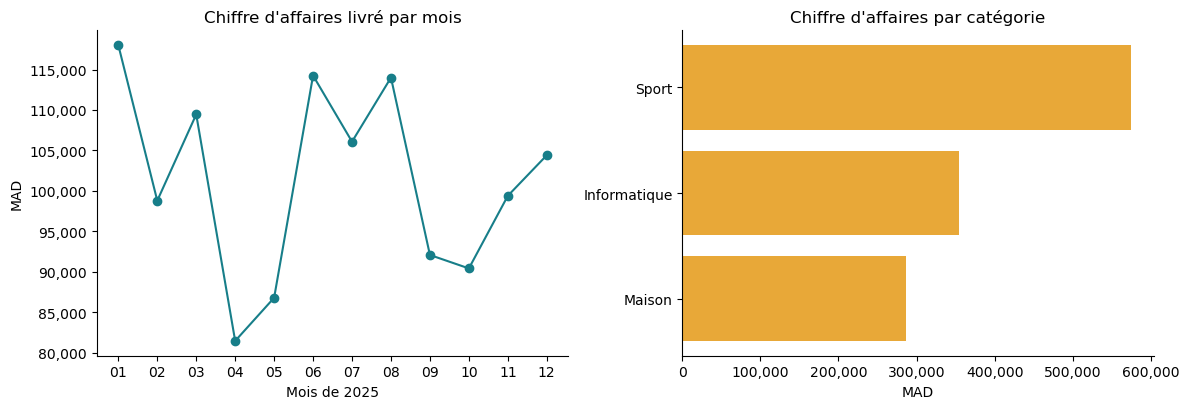

In [30]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10})
fig, axes = plt.subplots(1,2,figsize=(12,4.2))
mensuel_plot = ca_mensuel.orderBy("mois").collect()
axes[0].plot([r.mois[-2:] for r in mensuel_plot],[float(r.ca) for r in mensuel_plot],marker="o",color="#177e89")
axes[0].set(title="Chiffre d'affaires livré par mois",xlabel="Mois de 2025",ylabel="MAD")
categories_plot = ca_categories.orderBy("ca").collect()
axes[1].barh([r.categorie for r in categories_plot],[float(r.ca) for r in categories_plot],color="#e8a838")
axes[1].set(title="Chiffre d'affaires par catégorie",xlabel="MAD")
for ax in axes:
    ax.spines[["top","right"]].set_visible(False)
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda x,_:f"{x:,.0f}"))
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda x,_:f"{x:,.0f}"))
fig.tight_layout()
fig.savefig(ART/"resultats.png",dpi=180,bbox_inches="tight")
plt.show()

## Captures de l'exécution réelle
Storage est capturé en Q8.3 pendant que le cache des ventes est matérialisé.
Les captures SQL et Stages sont prises après l'ensemble des calculs. Les plans
textuels complets sont également conservés localement dans `artifacts/`.

**Spark UI — ventes conservées en cache (Q8.3)**

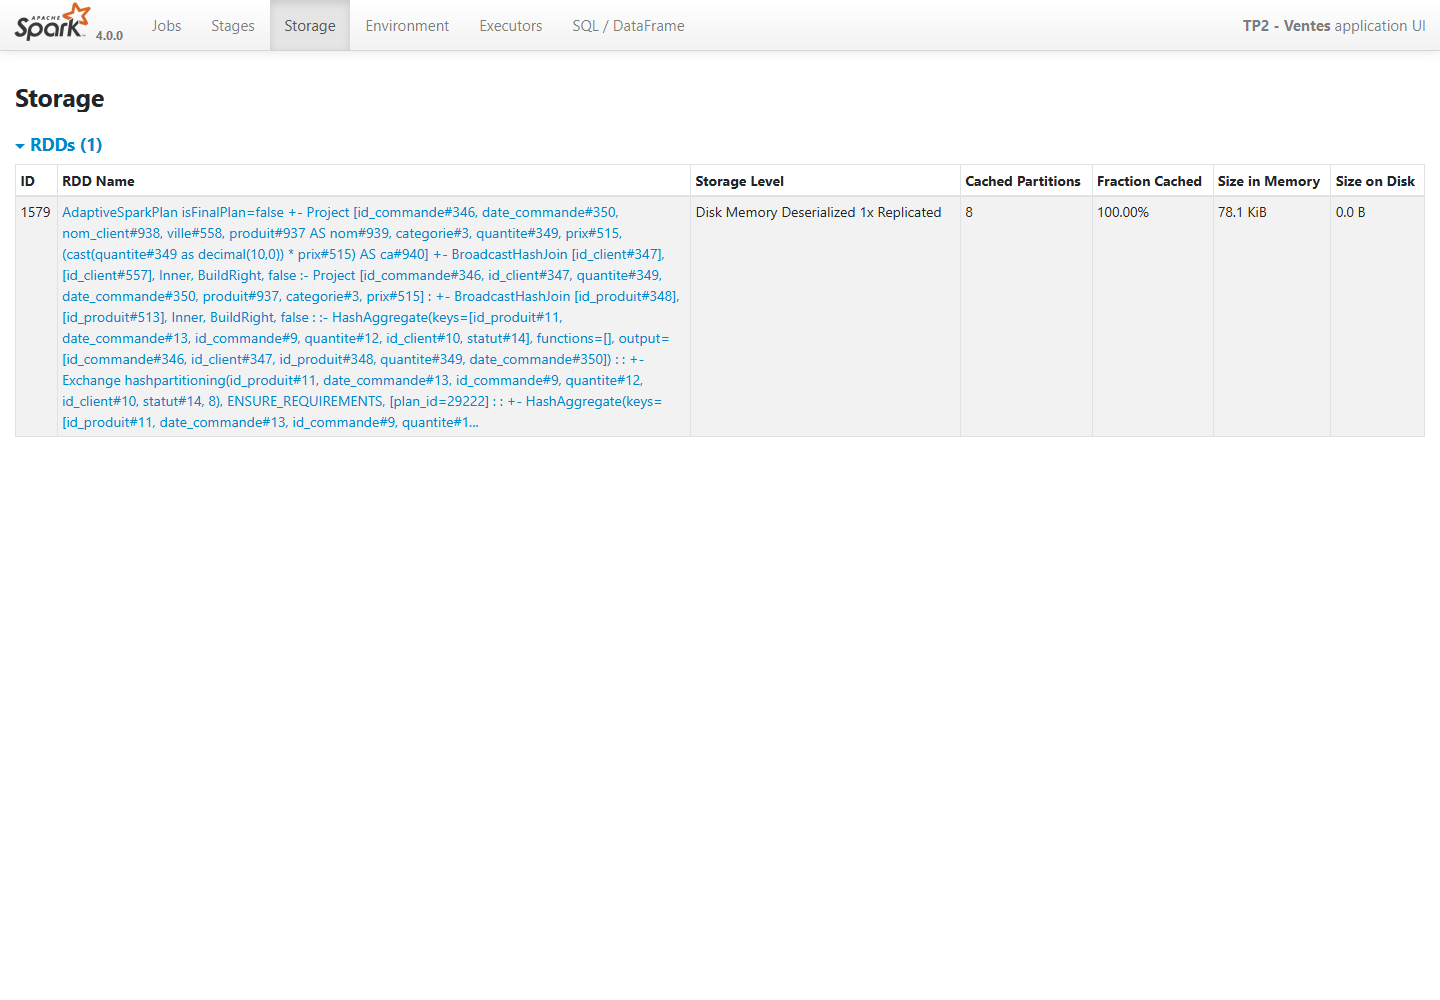

**Spark UI — exécutions SQL et DataFrame**

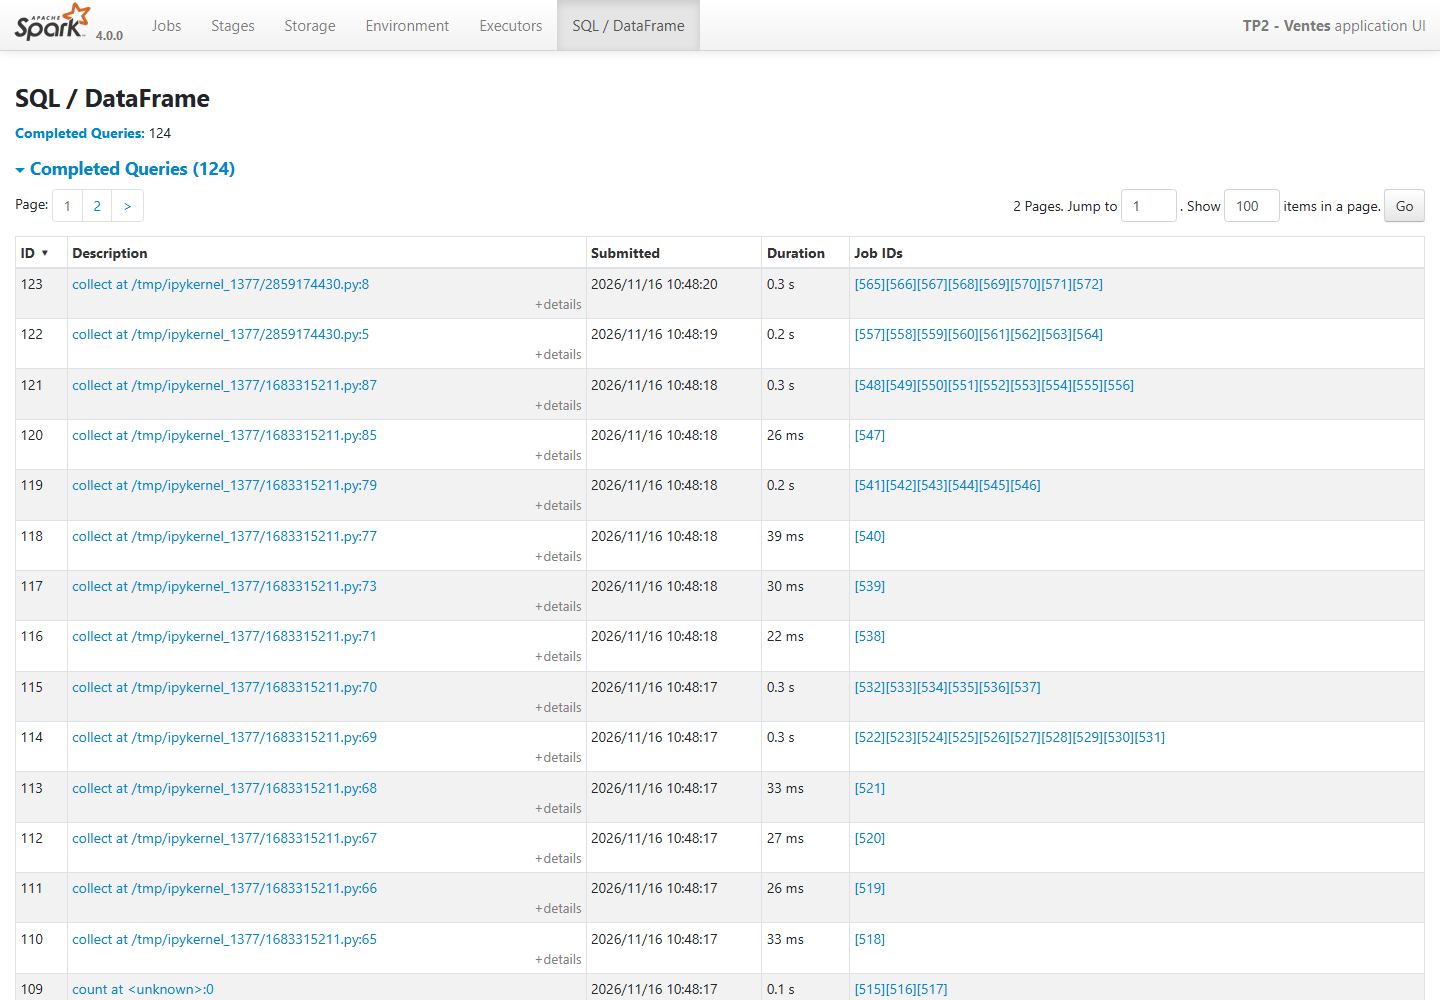

**Spark UI — détail d'une jointure broadcast**

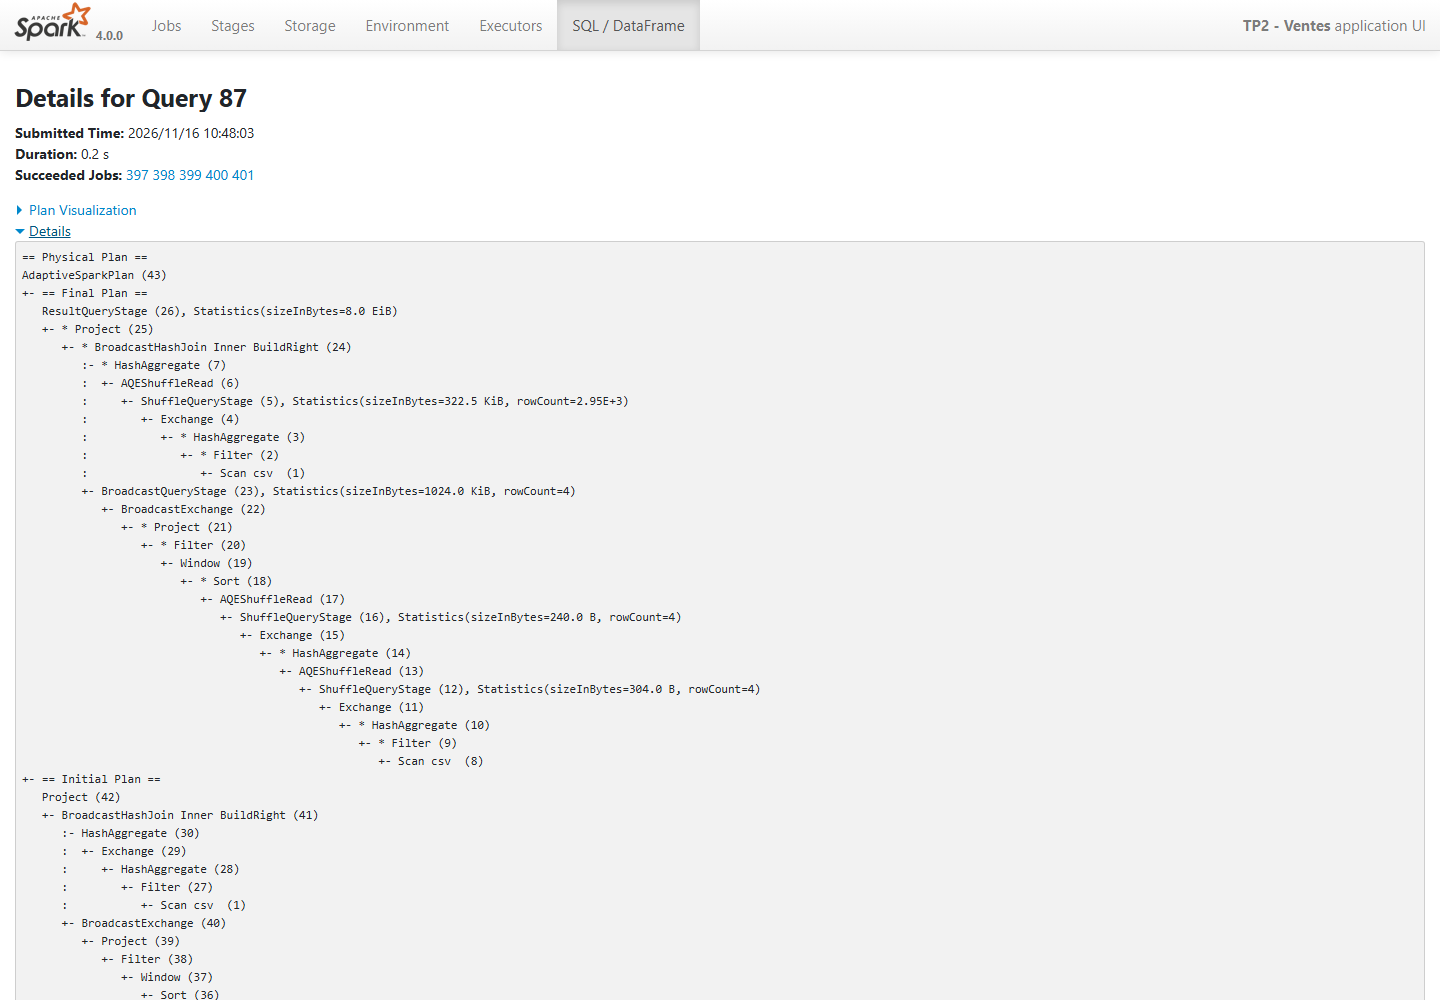

**Spark UI — stages réellement exécutés**

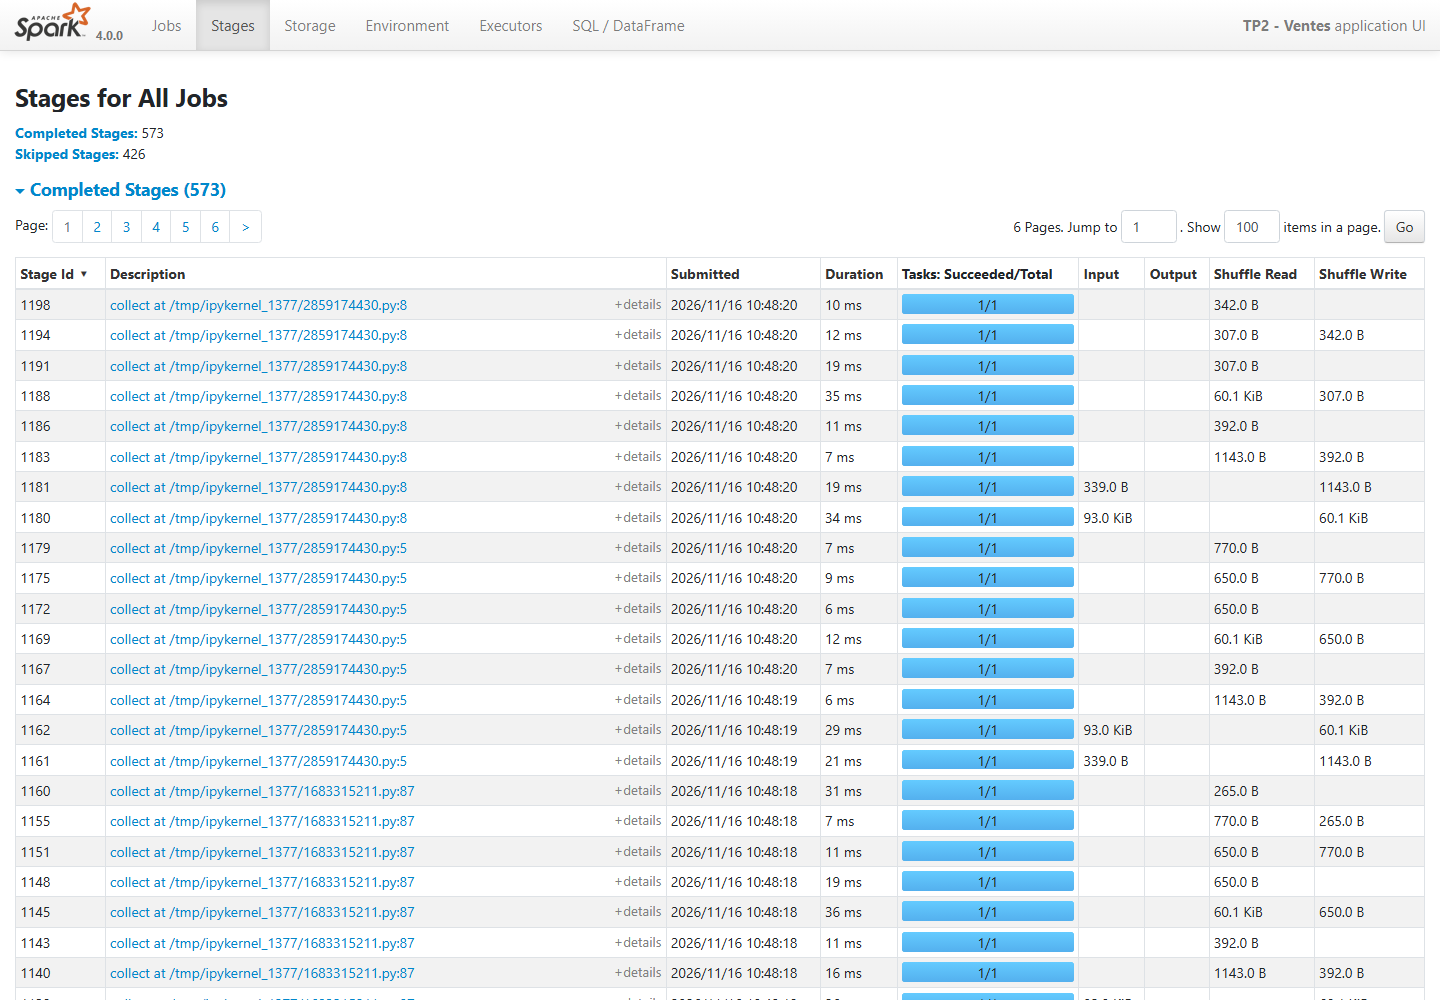

In [31]:
capture_attendre("final")
for fichier, legende in [("storage.png","Spark UI — ventes conservées en cache (Q8.3)"),
                          ("sql.png","Spark UI — exécutions SQL et DataFrame"),
                          ("sql_plan.png","Spark UI — détail d'une jointure broadcast"),
                          ("stages.png","Spark UI — stages réellement exécutés")]:
    chemin = CAP / fichier
    if chemin.exists():
        display(Markdown("**"+legende+"**"))
        display(Image(filename=str(chemin),width=1100))
    else:
        print("Capture conservée dans les sorties de la livraison initiale :",fichier)

## Références et reproduction
- Énoncé local : `TP4_SparkSQL_Analyse_Ventes.docx`, parties 0 à 9.
- Documentation Spark SQL 4.0.0 : https://spark.apache.org/docs/4.0.0/sql-programming-guide.html
- API PySpark : https://spark.apache.org/docs/4.0.0/api/python/reference/pyspark.sql/index.html

Ouvrir le notebook dans un noyau PySpark 4.0.0 avec Java 17, puis exécuter toutes les
cellules depuis un noyau neuf. La partie 0 recrée les données avec la graine 42.
Les sorties du TP sont remplacées en mode `overwrite`. Les captures intégrées sont
celles de la livraison ; les renouveler nécessite le script de capture du navigateur.
Les chronométrages de cache varient selon l'environnement. Le CSV fourni est la copie
exacte de l'unique fichier de données créé par l'export Spark de Q9.3.